# 01. 데이터 수집 노트북 — AI 생성 이미지 판별기

이 노트북 하나로 **실제 사진(real) / AI 생성 이미지(fake)** 를 여러 출처에서 모아
`256×256 JPEG(품질 90)` 으로 통일해 저장하고, 출처·라이선스·생성기 정보를 `manifest.csv` 에 기록합니다.

## 실행 전 설정 (Kaggle 오른쪽 패널)
1. **Settings → Accelerator: GPU T4 x2** (SDXL-Turbo 생성용)
2. **Settings → Internet: On** (Hugging Face 스트리밍용, 휴대폰 인증 필요)
3. **Add Data** 에서 아래 데이터셋 추가
   - `tristanzhang32/ai-generated-images-vs-real-images` (필수)
   - (선택) 내 폰 사진을 올린 내 데이터셋

## 수집 출처 요약
| 출처 | 라벨 | 용도 | 목표 장수 |
|---|---|---|---|
| Kaggle AI vs Real (SD·Midjourney·DALL-E / Pexels·Unsplash·WikiArt) | real + fake | 학습 풀 | 각 15,000 |
| ELSA D3 (Hugging Face, 확산모델 4종) | fake | 학습 풀 | 6,000 |
| ELSA D3 의 짝 실제 이미지 (LAION URL) | real | 학습 풀 | 최대 6,000 |
| FLUX.1-dev 생성 이미지 (HF) | fake | **처음 보는 생성기 테스트** | 1,000 |
| GPT-4o 생성 이미지 (HF) | fake | **처음 보는 생성기 테스트** | 1,000 |
| SDXL-Turbo **직접 생성** (한국 장면 프롬프트) | fake | **처음 보는 생성기 테스트** | 1,500 |
| 내 폰 사진 | real | 테스트 (실사용 환경) | 있는 만큼 |

> ⏱ 전체 실행 시간은 인터넷 속도에 따라 1~3시간 정도입니다. 출처별로 셀이 나뉘어 있어서 **중간에 끊겨도 이미 저장된 건 남아요.**
> 각 셀은 실패해도 다음 셀로 넘어갈 수 있게 만들었습니다.

## 끝나고 나서
오른쪽 위 **Save Version → Save & Run All** 로 저장한 뒤, Output 탭에서 **New Dataset** 을 누르면
`/kaggle/working/data` 가 내 비공개 데이터셋이 됩니다. 다음 노트북(전처리·학습)에서 그걸 Add Data 하면 돼요.

## 0. 설정

In [1]:
import os, io, json, hashlib, random, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import pandas as pd
from PIL import Image, ImageFile
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = None

SEED = 42
random.seed(SEED)

OUT = Path('/kaggle/working/data')
OUT.mkdir(parents=True, exist_ok=True)
ORIG_SAMPLES = OUT / '_orig_samples'     # 전처리 전·후 비교용 원본 샘플
ORIG_PER_SOURCE = 30                     # 출처마다 원본을 몇 장 보관할지

SIZE = 256        # 저장 해상도 (학습할 때 224로 랜덤 크롭)
JPEG_Q = 90       # 두 클래스 모두 같은 JPEG 품질로 재압축 → 형식 차이로 맞히는 지름길 차단
MIN_SIDE = 128    # 이보다 작은 이미지는 버림

# 출처별 목표 장수 (시간이 없으면 줄이세요)
TARGET = {
    'kaggle_real':   15000,
    'kaggle_fake':   15000,
    'elsa_fake':      6000,
    'elsa_real':      6000,   # URL 다운로드라 실제로는 더 적게 모일 수 있음
    'flux_unseen':    1000,
    'gpt4o_unseen':   1000,
    'sdxl_turbo':     1500,
}

MANIFEST = OUT / 'manifest.csv'
records, seen_hash, orig_count = [], set(), {}

# 이전 실행 결과가 있으면 이어서 진행
if MANIFEST.exists():
    _old = pd.read_csv(MANIFEST)
    records = _old.to_dict('records')
    seen_hash = {Path(p).stem for p in _old['path']}
    print(f'이전 기록 {len(records):,}건을 불러왔습니다.')

In [2]:
def to_square(img, size=SIZE):
    # 짧은 변을 size에 맞춰 줄인 뒤 가운데를 정사각형으로 자름
    img = img.convert('RGB')
    w, h = img.size
    s = size / min(w, h)
    img = img.resize((max(size, round(w * s)), max(size, round(h * s))), Image.BICUBIC)
    w, h = img.size
    l, t = (w - size) // 2, (h - size) // 2
    return img.crop((l, t, l + size, t + size))


def save(img, label, source, generator, license_, split_hint='pool', orig_format=None):
    # 이미지 1장을 표준 형식으로 저장하고 manifest에 기록. 저장되면 True.
    try:
        ow, oh = img.size
        fmt = orig_format or getattr(img, 'format', None) or 'unknown'
        if min(ow, oh) < MIN_SIDE:
            return False
        sq = to_square(img)
        buf = io.BytesIO()
        sq.save(buf, 'JPEG', quality=JPEG_Q)
        b = buf.getvalue()
        h = hashlib.md5(b).hexdigest()
        if h in seen_hash:              # 완전히 같은 이미지(중복) 제거
            return False
        seen_hash.add(h)
        d = OUT / label / source
        d.mkdir(parents=True, exist_ok=True)
        p = d / f'{h}.jpg'
        p.write_bytes(b)
        # 전·후 비교용 원본 샘플 보관
        if orig_count.get(source, 0) < ORIG_PER_SOURCE:
            od = ORIG_SAMPLES / source
            od.mkdir(parents=True, exist_ok=True)
            img.convert('RGB').save(od / f'{h}.png')
            orig_count[source] = orig_count.get(source, 0) + 1
        records.append(dict(
            path=str(p.relative_to(OUT)), label=label, source=source,
            generator=generator, license=license_, split_hint=split_hint,
            orig_w=ow, orig_h=oh, orig_format=str(fmt).upper(),
        ))
        return True
    except Exception:
        return False


def flush():
    pd.DataFrame(records).to_csv(MANIFEST, index=False)


def count(source):
    return sum(1 for r in records if r['source'] == source)


def is_nsfw(sample):
    for k in ('nsfw', 'NSFW', 'nsfw_label'):
        if k in sample and str(sample[k]).upper() in ('LIKELY', 'VERY_LIKELY', 'NSFW', 'TRUE', '1'):
            return True
    return False

print('준비 완료')

준비 완료


## 1. Kaggle 데이터셋 — AI-Generated Images vs Real Images
- 출처: https://www.kaggle.com/datasets/tristanzhang32/ai-generated-images-vs-real-images
- 라이선스: MIT (데이터셋 카드에서 한 번 더 확인하세요)
- 구성: fake = Stable Diffusion·Midjourney·DALL-E, real = Pexels·Unsplash·WikiArt

먼저 폴더 구조를 출력해서 확인합니다. 폴더 이름에 `fake`/`real` 이 들어 있으면 자동으로 라벨을 붙여요.

In [5]:
!find /kaggle/input -maxdepth 4 -type d | head -40

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/tristanzhang32
/kaggle/input/datasets/tristanzhang32/ai-generated-images-vs-real-images
/kaggle/input/datasets/tristanzhang32/ai-generated-images-vs-real-images/test
/kaggle/input/datasets/tristanzhang32/ai-generated-images-vs-real-images/train


In [7]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
FAKE_WORDS = ('fake', 'ai', 'ai_generated', 'aigenerated', 'synthetic', 'generated')
REAL_WORDS = ('real', 'nature', 'human', 'authentic')

def label_from_path(p):
    parts = [x.lower() for x in p.parts]
    if any(x in FAKE_WORDS for x in parts): return 'fake'
    if any(x in REAL_WORDS for x in parts): return 'real'
    return None

KAGGLE_DIR = Path('/kaggle/input/datasets/tristanzhang32/ai-generated-images-vs-real-images')
print('사용할 폴더:', KAGGLE_DIR, '| 존재:', KAGGLE_DIR.exists())
for sub in ('train', 'test'):
    print(sub, '→', [p.name for p in (KAGGLE_DIR / sub).iterdir()])

files = [p for p in KAGGLE_DIR.rglob('*') if p.suffix.lower() in IMG_EXT]
random.shuffle(files)
by_label = {'real': [], 'fake': []}
for p in files:
    lb = label_from_path(p.relative_to(KAGGLE_DIR))
    if lb: by_label[lb].append(p)
print({k: len(v) for k, v in by_label.items()})

for lb in ('real', 'fake'):
    src = f'kaggle_{lb}'
    need = TARGET[src] - count(src)
    gen = 'mixed(SD/Midjourney/DALL-E)' if lb == 'fake' else 'camera(Pexels/Unsplash/WikiArt)'
    pbar = tqdm(total=max(need, 0), desc=src)
    for p in by_label[lb]:
        if need <= 0: break
        try:
            with Image.open(p) as im:
                im.load()
                if save(im, lb, src, gen, 'MIT (Kaggle tristanzhang32)', 'pool', im.format):
                    need -= 1; pbar.update(1)
        except Exception:
            pass
    pbar.close()
    flush()
print({s: count(s) for s in ('kaggle_real', 'kaggle_fake')})

사용할 폴더: /kaggle/input/datasets/tristanzhang32/ai-generated-images-vs-real-images | 존재: True
train → ['fake', 'real']
test → ['fake', 'real']
{'real': 30000, 'fake': 30000}


kaggle_real:   0%|          | 0/15000 [00:00<?, ?it/s]

kaggle_fake:   0%|          | 0/15000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


{'kaggle_real': 15000, 'kaggle_fake': 15000}


## 2. ELSA D3 (Hugging Face 스트리밍) — 확산모델 4종 생성 이미지 + 짝이 되는 실제 이미지
- 출처: https://huggingface.co/datasets/elsaEU/ELSA_D3
- 한 레코드 = 프롬프트 1개 + 실제 이미지 URL 1개 + 생성 이미지 4장(생성기 4종)
- 라이선스: 데이터셋 카드에서 확인 후 README에 적으세요 (ELSA 시리즈의 다른 데이터셋은 CC BY 4.0)
- 전체를 받지 않고 **스트리밍**으로 필요한 만큼만 가져옵니다.

In [8]:
from datasets import load_dataset

def image_fields(sample):
    return [k for k, v in sample.items() if isinstance(v, Image.Image)]

try:
    elsa = load_dataset('elsaEU/ELSA_D3', split='train', streaming=True)
    first = next(iter(elsa))
    print('필드 목록:')
    for k, v in first.items():
        print(f'  {k:25s} {type(v).__name__:12s} {str(v)[:60] if not isinstance(v, Image.Image) else v.size}')
except Exception as e:
    elsa = None
    print('ELSA 불러오기 실패:', e)

README.md:   0%|          | 0.00/4.38k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/5254 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/5254 [00:00<?, ?it/s]

필드 목록:
  id                        str          2848878015413
  original_prompt           str          munthirivallikal thalirkkumbol latest news, munthirivallikal
  positive_prompt           str          An image of munthirivallikal thalirkkumbol latest news, munt
  negative_prompt           str          
  url                       str          http://onlookersmedia.in/wp-content/uploads/2017/04/munthiri
  model_gen0                str          DeepFloyd/IF-II-L-v1.0
  model_gen1                str          CompVis/stable-diffusion-v1-4
  model_gen2                str          stabilityai/stable-diffusion-2-1-base
  model_gen3                str          stabilityai/stable-diffusion-xl-base-1.0
  width_gen0                int          256
  width_gen1                int          512
  width_gen2                int          640
  width_gen3                int          640
  height_gen0               int          256
  height_gen1               int          512
  height_gen2           

In [9]:
ELSA_LICENSE = 'see dataset card (elsaEU/ELSA_D3)'
real_urls = []

if elsa is not None:
    need = TARGET['elsa_fake'] - count('elsa_fake')
    pbar = tqdm(total=max(need, 0), desc='elsa_fake')
    for s in elsa.shuffle(seed=SEED, buffer_size=200):
        if need <= 0: break
        if is_nsfw(s): continue
        url = s.get('url') or s.get('url_real_image')
        if url: real_urls.append(url)
        for k in image_fields(s):
            # image_gen0 → model_gen0 처럼 생성기 이름 필드를 찾아봄
            gen = s.get(k.replace('image', 'model')) or s.get('model') or k
            if save(s[k], 'fake', 'elsa_fake', str(gen), ELSA_LICENSE, 'pool', 'PNG'):
                need -= 1; pbar.update(1)
            if need <= 0: break
    pbar.close()
    flush()
print('elsa_fake:', count('elsa_fake'), '| 모은 실제 이미지 URL:', len(real_urls))

elsa_fake:   0%|          | 0/6000 [00:00<?, ?it/s]

elsa_fake: 6000 | 모은 실제 이미지 URL: 1500


### 2-1. ELSA 짝 실제 이미지 (LAION URL 다운로드)
같은 프롬프트에서 나온 **실제 사진**이라, 내용은 비슷하고 진짜/가짜만 다른 좋은 비교 데이터가 됩니다.
오래된 URL이 많아서 실패가 많은 게 정상이에요. 실패한 건 건너뜁니다.

In [11]:
import requests

def fetch(url):
    try:
        r = requests.get(url, timeout=6, headers={'User-Agent': 'Mozilla/5.0'})
        if r.status_code != 200 or len(r.content) < 5000:
            return None
        im = Image.open(io.BytesIO(r.content)); im.load()
        return im
    except Exception:
        return None

need = TARGET['elsa_real'] - count('elsa_real')
pbar = tqdm(total=max(need, 0), desc='elsa_real')
with ThreadPoolExecutor(max_workers=32) as ex:
    futs = [ex.submit(fetch, u) for u in real_urls]
    for f in as_completed(futs):
        if need <= 0: break
        im = f.result()
        if im is not None and save(im, 'real', 'elsa_real', 'camera(LAION-400M)',
                                   'LAION-400M URL (원 저작권은 각 이미지 소유자)', 'pool', im.format):
            need -= 1; pbar.update(1)
pbar.close()
flush()
print('elsa_real:', count('elsa_real'))

elsa_real:   0%|          | 0/5148 [00:00<?, ?it/s]

elsa_real: 866


## 3. 처음 보는 생성기 테스트셋 — FLUX.1-dev, GPT-4o
학습에 **전혀 쓰지 않을** 최신 생성기 이미지입니다. `split_hint='unseen'` 으로 표시해 두고, 다음 노트북에서 테스트 전용으로 씁니다.
- FLUX: https://huggingface.co/datasets/lehduong/flux_generated
- GPT-4o: https://huggingface.co/datasets/yufan/GPT4O_Image_T2I

두 데이터셋 모두 **라이선스를 카드에서 꼭 확인**하세요. 불러오기에 실패하면 이 셀은 건너뛰고, 4번(직접 생성)만으로도 충분합니다.

In [12]:
def stream_hf(repo, n, label, source, generator, license_, split_hint, split='train', config=None):
    try:
        ds = load_dataset(repo, config, split=split, streaming=True)
    except Exception as e:
        print(f'[{repo}] 불러오기 실패: {e}')
        return
    need = n - count(source)
    pbar = tqdm(total=max(need, 0), desc=source)
    try:
        for s in ds.shuffle(seed=SEED, buffer_size=200):
            if need <= 0: break
            if is_nsfw(s): continue
            for k in image_fields(s):
                if save(s[k], label, source, generator, license_, split_hint):
                    need -= 1; pbar.update(1)
                if need <= 0: break
    except Exception as e:
        print(f'[{repo}] 중간에 멈춤: {e}')
    pbar.close()
    flush()
    print(source, count(source))

stream_hf('lehduong/flux_generated', TARGET['flux_unseen'], 'fake', 'flux_unseen',
          'FLUX.1-dev', 'see dataset card (lehduong/flux_generated)', 'unseen')
stream_hf('yufan/GPT4O_Image_T2I', TARGET['gpt4o_unseen'], 'fake', 'gpt4o_unseen',
          'GPT-4o', 'see dataset card (yufan/GPT4O_Image_T2I)', 'unseen')

README.md:   0%|          | 0.00/407 [00:00<?, ?B/s]

[lehduong/flux_generated] 불러오기 실패: Dataset 'lehduong/flux_generated' is a gated dataset on the Hub. You must be authenticated to access it.


README.md:   0%|          | 0.00/325 [00:00<?, ?B/s]

gpt4o_unseen:   0%|          | 0/1000 [00:00<?, ?it/s]

gpt4o_unseen 1000


## 4. ⭐ 직접 생성 — SDXL-Turbo (한국 일상 장면)
**직접 만든 데이터**라서 README의 차별점에 쓸 수 있어요. "기존 데이터셋에 없는 한국 일상 장면 + 최신 생성기"
- 모델: https://huggingface.co/stabilityai/sdxl-turbo (1단계 생성이라 T4에서도 빠름)
- 라이선스: Stability AI 비상업 연구용 라이선스 → 과제 용도는 OK (모델 카드에서 확인)
- 인물 얼굴은 넣지 않았습니다.

In [13]:
!pip -q install -U diffusers accelerate

In [14]:
import torch
from diffusers import AutoPipelineForText2Image

pipe = AutoPipelineForText2Image.from_pretrained(
    'stabilityai/sdxl-turbo', torch_dtype=torch.float16, variant='fp16').to('cuda')
pipe.set_progress_bar_config(disable=True)

SUBJECTS = [
    'a bowl of bibimbap', 'tteokbokki at a street food stall', 'a Korean convenience store shelf',
    'a narrow alley in Seoul', 'a subway platform in Seoul', 'a hanok roof', 'a cafe table with iced americano',
    'a university lecture hall', 'an apartment complex at dusk', 'a han river park', 'a bus stop on a rainy day',
    'a cat sleeping on a sofa', 'a dog on a walk', 'a desk with a laptop and notes', 'a bicycle parked by a wall',
    'cherry blossoms on a street', 'autumn leaves in a park', 'a mountain hiking trail', 'a beach in Busan',
    'a traditional market', 'a bowl of ramen', 'a plate of fried chicken', 'a stack of books', 'a houseplant by a window',
    'a kitchen counter', 'a parking lot at night', 'a neon sign street at night', 'a snowy road', 'a soccer ball on grass',
    'a pair of sneakers', 'a fruit stand with apples', 'a coffee machine', 'an empty classroom',
]
STYLES = [
    'shot on smartphone', 'DSLR photo, 35mm', 'casual snapshot', 'photo, natural light', 'photo, overcast day',
    'photo, golden hour', 'photo, indoor lighting', 'photo, slightly blurry', 'close-up photo', 'wide angle photo',
]

need = TARGET['sdxl_turbo'] - count('sdxl_turbo')
BATCH = 8
g = torch.Generator('cuda').manual_seed(SEED)
pbar = tqdm(total=max(need, 0), desc='sdxl_turbo')
while need > 0:
    prompts = [f'{random.choice(SUBJECTS)}, {random.choice(STYLES)}, realistic' for _ in range(BATCH)]
    with torch.inference_mode():
        imgs = pipe(prompt=prompts, num_inference_steps=1, guidance_scale=0.0, generator=g).images
    for im in imgs:
        if need > 0 and save(im, 'fake', 'sdxl_turbo', 'SDXL-Turbo',
                             'own generation (SDXL-Turbo, Stability AI non-commercial license)', 'unseen', 'PNG'):
            need -= 1; pbar.update(1)
pbar.close()
flush()
del pipe; torch.cuda.empty_cache()
print('sdxl_turbo:', count('sdxl_turbo'))

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

sdxl_turbo:   0%|          | 0/1500 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:750: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


OutOfMemoryError: CUDA out of memory. Tried to allocate 2.00 GiB. GPU 0 has a total capacity of 14.56 GiB of which 596.81 MiB is free. Including non-PyTorch memory, this process has 13.98 GiB memory in use. Of the allocated memory 10.24 GiB is allocated by PyTorch, and 3.61 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [17]:
import gc
gc.collect(); torch.cuda.empty_cache()

from diffusers import AutoencoderKL
pipe.vae = AutoencoderKL.from_pretrained('madebyollin/sdxl-vae-fp16-fix',
                                         torch_dtype=torch.float16).to('cuda')
pipe.vae.enable_slicing()   # 이미지를 한 장씩 디코딩 → 메모리 절약
pipe.vae.enable_tiling()
gc.collect(); torch.cuda.empty_cache()

BATCH = 4
need = TARGET['sdxl_turbo'] - count('sdxl_turbo')
g = torch.Generator('cuda').manual_seed(SEED)
pbar = tqdm(total=max(need, 0), desc='sdxl_turbo')
while need > 0:
    prompts = [f'{random.choice(SUBJECTS)}, {random.choice(STYLES)}, realistic' for _ in range(BATCH)]
    with torch.inference_mode():
        imgs = pipe(prompt=prompts, num_inference_steps=1, guidance_scale=0.0, generator=g).images
    for im in imgs:
        if need > 0 and save(im, 'fake', 'sdxl_turbo', 'SDXL-Turbo',
                             'own generation (SDXL-Turbo, Stability AI non-commercial license)', 'unseen', 'PNG'):
            need -= 1; pbar.update(1)
pbar.close()
flush()
del pipe; gc.collect(); torch.cuda.empty_cache()
print('sdxl_turbo:', count('sdxl_turbo'))

config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

sdxl_turbo:   0%|          | 0/1500 [00:00<?, ?it/s]

sdxl_turbo: 1500


## 5. (선택) 내 폰 사진
폰 사진을 zip으로 묶어 **내 Kaggle 데이터셋**으로 올리고 Add Data 한 뒤, 아래 `MY_PHOTO_DIR` 를 그 경로로 바꾸세요.
아이폰 HEIC 사진도 읽을 수 있게 `pillow-heif` 를 설치합니다.
실제 사용 환경(폰 카메라, 다양한 조명)의 real 이미지라서 테스트용으로 씁니다.

In [18]:
!pip -q install pillow-heif
try:
    from pillow_heif import register_heif_opener; register_heif_opener()
except Exception as e:
    print('HEIC 지원 없음:', e)

MY_PHOTO_DIR = Path('/kaggle/input/my-phone-photos')   # ← 내 데이터셋 경로로 바꾸기
if MY_PHOTO_DIR.exists():
    exts = IMG_EXT | {'.heic', '.heif'}
    files = [p for p in MY_PHOTO_DIR.rglob('*') if p.suffix.lower() in exts]
    n = 0
    for p in tqdm(files, desc='my_photos'):
        try:
            with Image.open(p) as im:
                im.load()
                if save(im, 'real', 'my_photos', 'camera(my smartphone)', 'own photos (본인 촬영)', 'unseen', im.format):
                    n += 1
        except Exception:
            pass
    flush()
    print('my_photos:', n)
else:
    print('폰 사진 폴더가 없어서 건너뜁니다.')

폰 사진 폴더가 없어서 건너뜁니다.


## 6. 수집 결과 요약 (README `## 2. 데이터` 에 그대로 쓰세요)

총 39,366장



,source,label,split_hint,generator,license,count
0,elsa_fake,fake,pool,CompVis/stable-diffusion-v1-4,see dataset card (elsaEU/ELSA_D3),1500
1,elsa_fake,fake,pool,DeepFloyd/IF-II-L-v1.0,see dataset card (elsaEU/ELSA_D3),1500
2,elsa_fake,fake,pool,stabilityai/stable-diffusion-2-1-base,see dataset card (elsaEU/ELSA_D3),1500
3,elsa_fake,fake,pool,stabilityai/stable-diffusion-xl-base-1.0,see dataset card (elsaEU/ELSA_D3),1500
6,kaggle_fake,fake,pool,mixed(SD/Midjourney/DALL-E),MIT (Kaggle tristanzhang32),15000
4,elsa_real,real,pool,camera(LAION-400M),LAION-400M URL (원 저작권은 각 이미지 소유자),866
7,kaggle_real,real,pool,camera(Pexels/Unsplash/WikiArt),MIT (Kaggle tristanzhang32),15000
5,gpt4o_unseen,fake,unseen,GPT-4o,see dataset card (yufan/GPT4O_Image_T2I),1000
8,sdxl_turbo,fake,unseen,SDXL-Turbo,"own generation (SDXL-Turbo, Stability AI non-c...",1500



[클래스 분포]


label,fake,real
split_hint,,
pool,21000,15866
unseen,2500,0


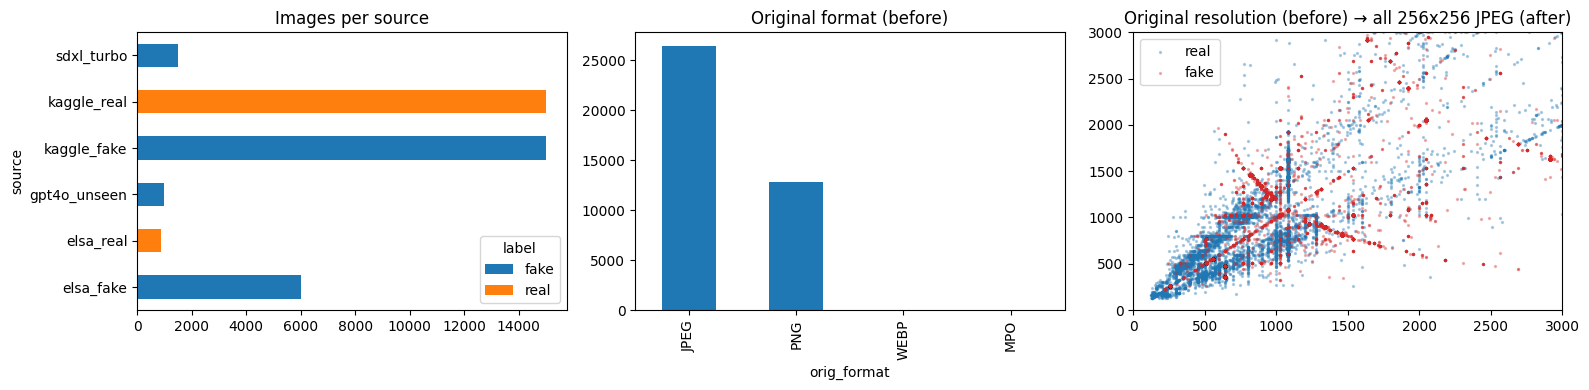


저장 위치: /kaggle/working/data
1.3G	/kaggle/working/data


In [19]:
import matplotlib.pyplot as plt

df = pd.read_csv(MANIFEST)
print(f'총 {len(df):,}장\n')

summary = (df.groupby(['source', 'label', 'split_hint', 'generator', 'license'])
             .size().reset_index(name='count').sort_values(['split_hint', 'label', 'source']))
display(summary)

print('\n[클래스 분포]')
display(df.groupby(['split_hint', 'label']).size().unstack(fill_value=0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby(['source', 'label']).size().unstack(fill_value=0).plot.barh(ax=axes[0], stacked=True)
axes[0].set_title('Images per source')
df['orig_format'].value_counts().head(8).plot.bar(ax=axes[1], title='Original format (before)')
for lb, c in (('real', 'tab:blue'), ('fake', 'tab:red')):
    d = df[df.label == lb]
    axes[2].scatter(d.orig_w, d.orig_h, s=2, alpha=.3, label=lb, c=c)
axes[2].set_xlim(0, 3000); axes[2].set_ylim(0, 3000)
axes[2].set_title('Original resolution (before) → all 256x256 JPEG (after)'); axes[2].legend()
plt.tight_layout()
plt.savefig(OUT / 'collection_summary.png', dpi=120)
plt.show()

summary.to_csv(OUT / 'collection_summary.csv', index=False)
print('\n저장 위치:', OUT)
!du -sh /kaggle/working/data

### 원본(전) vs 저장본(후) 비교
전처리 **전·후 비교(B2)** 자료로 쓰세요. 원본은 형식·해상도가 제각각이지만, 저장본은 모두 256×256 JPEG입니다.

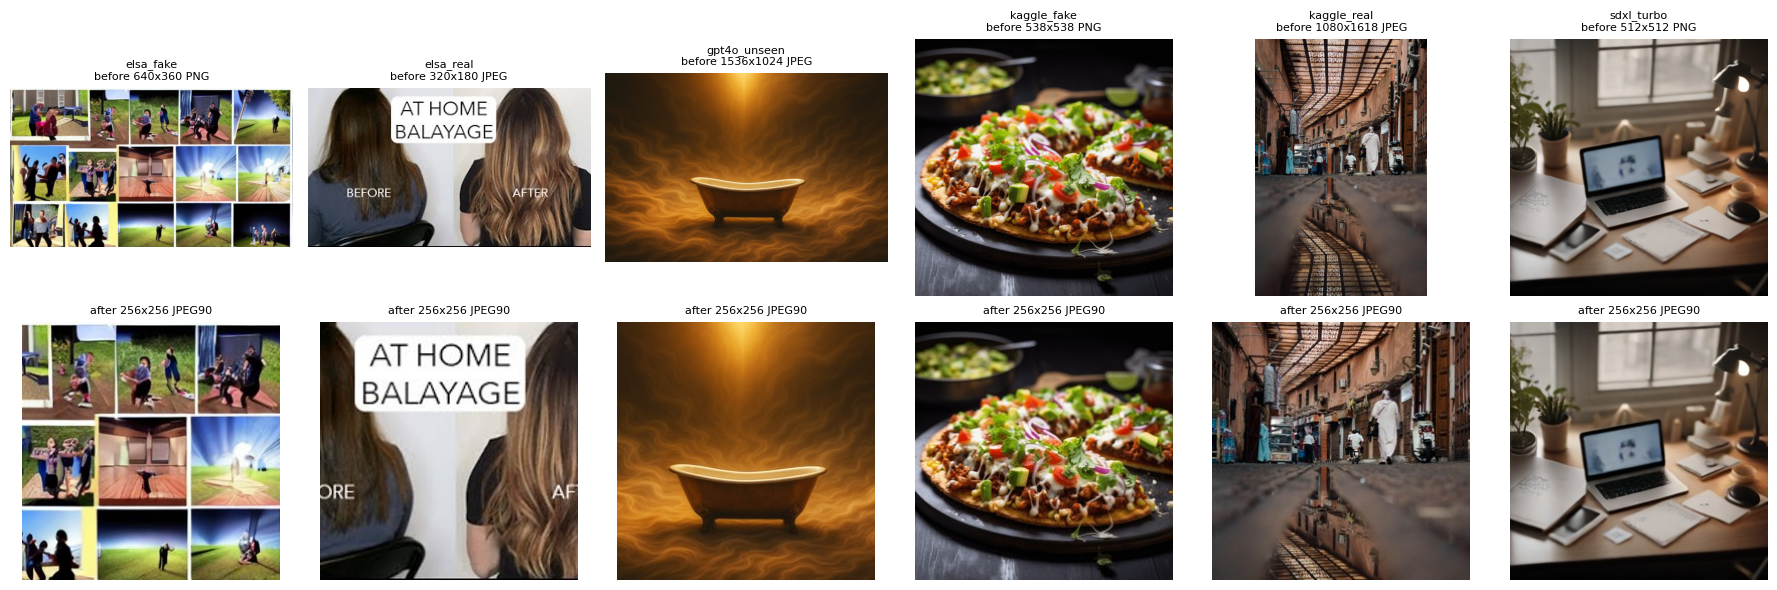

In [20]:
srcs = sorted([p.name for p in ORIG_SAMPLES.iterdir()]) if ORIG_SAMPLES.exists() else []
fig, axes = plt.subplots(2, len(srcs), figsize=(3 * len(srcs), 6), squeeze=False)
for i, s in enumerate(srcs):
    o = sorted((ORIG_SAMPLES / s).glob('*.png'))[0]
    rec = df[df.path.str.contains(o.stem)].iloc[0]
    oi = Image.open(o)
    axes[0, i].imshow(oi); axes[0, i].set_title(f'{s}\nbefore {oi.size[0]}x{oi.size[1]} {rec.orig_format}', fontsize=8)
    axes[1, i].imshow(Image.open(OUT / rec.path)); axes[1, i].set_title('after 256x256 JPEG90', fontsize=8)
for a in axes.flat: a.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'before_after.png', dpi=120); plt.show()

In [21]:
!cd /kaggle/working && zip -q -r -0 data.zip data && ls -lh data.zip

-rw-r--r-- 1 root root 1.2G Nov 16 11:44 data.zip


In [22]:
!rm -rf /kaggle/working/data && ls -lh /kaggle/working

total 1.2G
-rw-r--r-- 1 root root 1.2G Nov 16 11:44 data.zip
